# DSA8002 Coursework Question 1 [50 Marks]

---

In this assignment, you will write a Python program that simulates, analyzes, and visualizes temperature data for a fictional city in the Northern hemisphere over the course of one year (365 days).

Complete the tasks below using this Jupyter notebook. For each task, you have been provided with code and markdown cells (if applicable) to enter your answers.

You may add additional code or markdown cells if required, e.g. for testing code.
    
Ensure that all code cells are **fully commented**. Code without detailed comments will lose marks.

You must import any required packages at the beginning of this notebook.

**Execute all cells before saving and submitting!**


---

In [1]:
# Import packages here
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

Setting seed

In [2]:
# Setting seed
np.random.seed(20)

---

## Task 1: Generate synthetic temperature data 

Using `numpy`, write a function called `generate_temperature_data()` that simulates daily temperatures for 365 days.

Use a sine or cosine function to ensure overall seasonal changes, i.e. warmer in summer, colder in winter.

Add random noise using a normal distribution to simulate daily variation.

The function must return a numpy array of length 365, with index 0 corresponding to January 1st.

Use the following parameters for the seasonal and daily variation:

 - The average temperature over the course of the year is 15 degrees, and the amplitude of the seasonal variation is ±10 degrees (i.e. the seasonal variation runs from 5 to 25 degrees).

 - The standard deviation of the random day-to-day variability is 2 degrees (you can use this argument directly in `np.random`'s normal distribution function).

**Hint**: The sine/cosine functions in Numpy expect arguments in radians, so they are periodic over the interval `[0, 2*np.pi]`. If you want to create a sine wave with a different period (e.g. 365 days), multiply the argument of the function by `2*np.pi/period`.
                                                                             
### Function:

In [3]:
# Function that generates daily temperature data for 365 days using random noise and seasonal temperature variation
def generate_temperature_data():

    # Total number of days to simulate daily temperature for
    num_days = 365

    # Generates a numpy array of days from 0 to 364 ( January 1st = Index 0)
    days = np.arange(num_days)

    # Average temperature
    avg_temp = 15

    # Seasonal temperature variation
    temp_amplitude = 10

    # Day-to-day random temperature variation
    temp_std = 2

    # Generates random noise on a normal distribution (mean = 0, std = 2, size = 365)
    noise = np.random.normal(0, temp_std, num_days)

    # Generates seasonal temperature variation using a sine wave
    # with a phase shift of -pi/2 to ensure coldest temperatures occur near January and December
    seasonal_variation = temp_amplitude * np.sin(2 * np.pi * days / num_days - np.pi / 2)
    
    # Combines average temperature, seasonal variation and noise
    temperatures = avg_temp + seasonal_variation + noise

    return temperatures

### Create the temperature data using your function:

In [4]:
# Calls the generate_temperature_data function
temperature_data = generate_temperature_data()

---

## Task 2: Compute statistics on the data 

Create a function called `analyse_temperatures()` that takes a single argument (your temperature data) and calculates the following statistics:

 - The average temperature for the year

 - The hottest day and the coldest day (both the index and the temperature value for each)

 - A list containing the average temperature in each 30 day window, up to day 360 (this should produce 12 values, approximating the monthly averages)

The function should return this information as a **dictionary**.

### Function:

In [5]:
# Function that calculates average temperature for 365 days,
# gets hottest temperatures's index and coldest temoperature's index and corresponding temperature value and
# calculates the average temperature for each month (30 day windows)
def analyse_temperatures(temperatures):
    
    # Calculates average temperature over 365 days
    avg_temp = np.mean(temperatures)

    # Gets hottest day and corresponding temperature
    hottest_day = np.argmax(temperatures)
    hottest_temp = temperatures[hottest_day]

    # Gets coldest day and corresponding temperature
    coldest_day = np.argmin(temperatures)
    coldest_temp = temperatures[coldest_day]

    # Calculates monthly average temperatures (Assuming each month is 30 days long)
    monthly_avg_temps = []

    # Loops through 30 day windows
    for i in range(0, 360, 30):

        # Gets daily temperatures for the month
        month_temps = temperatures[i:i+30]

        # Calculates average temperature for the month
        month_avg_temp = np.mean(month_temps)

        # Appends average temperature to the list
        monthly_avg_temps.append(month_avg_temp)

    # Returns results in a dictionary
    return  {"average_temperature": avg_temp,
               "hottest_day": (hottest_day, hottest_temp),
               "coldest_day": (coldest_day, coldest_temp),
               "monthly_average_temperatures": monthly_avg_temps}

### Execute this function and **print the output**:

In [6]:
# Calls the analyse_temperature function
temperature_analysis = analyse_temperatures(temperature_data)

# Prints the results
print(f"Annual Average Temperature: {temperature_analysis['average_temperature']:.2f}\u2103")
print(f"Hottest Day: Day {temperature_analysis['hottest_day'][0]} with a temperature of {temperature_analysis['hottest_day'][1]:.2f}\u2103")
print(f"Coldest Day: Day {temperature_analysis['coldest_day'][0]} with a temperature of {temperature_analysis['coldest_day'][1]:.2f}\u2103")

print("Monthly Average Temperatures:")

# Loops through monthly average temperatures and prints them
for i, month_avg in enumerate(temperature_analysis['monthly_average_temperatures']):
    print(f"    Month {i + 1}: {month_avg:.2f}\u2103")

Annual Average Temperature: 15.08℃
Hottest Day: Day 178 with a temperature of 28.88℃
Coldest Day: Day 21 with a temperature of -0.73℃
Monthly Average Temperatures:
    Month 1: 5.27℃
    Month 2: 7.98℃
    Month 3: 12.27℃
    Month 4: 16.80℃
    Month 5: 22.02℃
    Month 6: 24.97℃
    Month 7: 24.71℃
    Month 8: 22.07℃
    Month 9: 18.12℃
    Month 10: 13.08℃
    Month 11: 9.81℃
    Month 12: 5.56℃


### Comment on your results, do these numbers match your expectations?

- The results give an annual average temperature of $15.08 ^\circ C$ (to $2$ d.p), which is close to the model's specified average temperature of $15 ° C$.

- The hottest day occurs at day $178$, which corresponds to June $28^{\text{th}}$, with a temperature of $28.88 ^\circ C$ (to $2$ d.p). This maximum occurs during summer in the Northern Hemisphere and is within 3 standard deviations of the average temperature for June, which has the highest average monthly temperature.

- The coldest day occurs at day $21$, which corresponds to January $22^{\text{nd}}$, with a temperature of $-0.73 ^\circ C$ (to $2$ d.p). This minimum occurs during winter in the Northern Hemisphere and is within 3 standard deviations of the average temperature for January, which has the lowest average monthly temperature.

- The average monthly temperatures show a trend of increasing as the season goes from winter to spring to summer and then shows a trend of decreasing as the season goes from summer to autumn to winter.

Overall, the results align with expectations from a sinusoidal seasonal model and reflect realistic temperature variation throughout the course of a year, where temperatures rises through the middle of the year and drops during winter.

---

## Task 3: Visualise the data

Write a function called `plot_temperatures()` that takes a single argument (your temperature data) and uses this to plot the daily temperature data using `Matplotlib`.

The function should highlight the hottest and coldest day using different markers.


**Optional bonus**: Plot a smoothed temperature curve using a rolling average. It is up to you what size of time bins to use to compute these averages.

### Rolling Average Function:

In [7]:
# Function that calculates a centered rolling average over the temperature data,
# using a time bin to define the size of window for which the rolling average is calculated.
# This process is repeated for each day while also handling edge cases
def calc_rolling_average(temps, time_bin):

    # Gets total number of days 
    num_days = len(temps)

    # Calculates half the time_bin and rounds down to the nearest integer
    half_time_bin = time_bin // 2

    # Creates a numpy array of zeros of length num_days
    rolling_avg = np.zeros(num_days)

    # Loops through all the days
    for i in range(num_days):

        # Sets start day using max() to prevent window from going out of bounds at edge
        start_day = max(0, i - half_time_bin)

        # Sets end day using min() to prevent window from going out of bounds at edge
        end_day = min(num_days, i + half_time_bin + 1)

        # Calculates the mean of all temperature values within the window 
        rolling_avg[i] = np.mean(temps[start_day:end_day])

    return rolling_avg

### Function:

In [8]:
# Function that plots daily temperatures over 365 days,
# highlights hottest and coldest days with unique markers and 
# plots a 15-day rolling average
def plot_temperatures(temperatures):
    
    # Generates a numpy array of days from 0 to 364 ( January 1st = Index 0)
    days = np.arange(len(temperatures))

    # Rolling average time bin
    time_bin = 15

    # Gets hottest day and corresponding temperature value
    hottest_day = np.argmax(temperatures)
    hottest_temp = temperatures[hottest_day]

    # Gets coldest day and corresponding temperature value
    coldest_day = np.argmin(temperatures)
    coldest_temp = temperatures[coldest_day]

    # Calls the calc_rolling_average function
    rolling_avg_temps = calc_rolling_average(temperatures, time_bin)

    # Creates the plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Plots daily temperatures using a black line
    ax.plot(days, temperatures, color='black', label = "Daily Temperatures", )
    
    # Plots rolling average temperatures using a purple line
    ax.plot(days, rolling_avg_temps, color='darkblue', label=f'{time_bin}-Day Rolling Average')

    # Highlights hottest and coldest days
    ax.scatter(hottest_day, hottest_temp, color='red', marker='x', label = 'Hottest Day')
    ax.scatter(coldest_day, coldest_temp, color='blue', marker='o', label = 'Coldest Day')

    # Sets x and y labels
    ax.set_xlabel("Number of Days Since January 1$^{st}$")
    ax.set_ylabel("Temperature (\u2103)")

    # Sets title
    ax.set_title("Daily Temperature Over 365 Days")

    # Displays legend and locks it to the top right
    ax.legend(loc='upper right')

    # Displays grid
    ax.grid()

    # Saves the plot as a png
    plt.savefig("daily_temperatures.png")

    # Displays the plot
    #plt.show()

### Create the plot using your function:

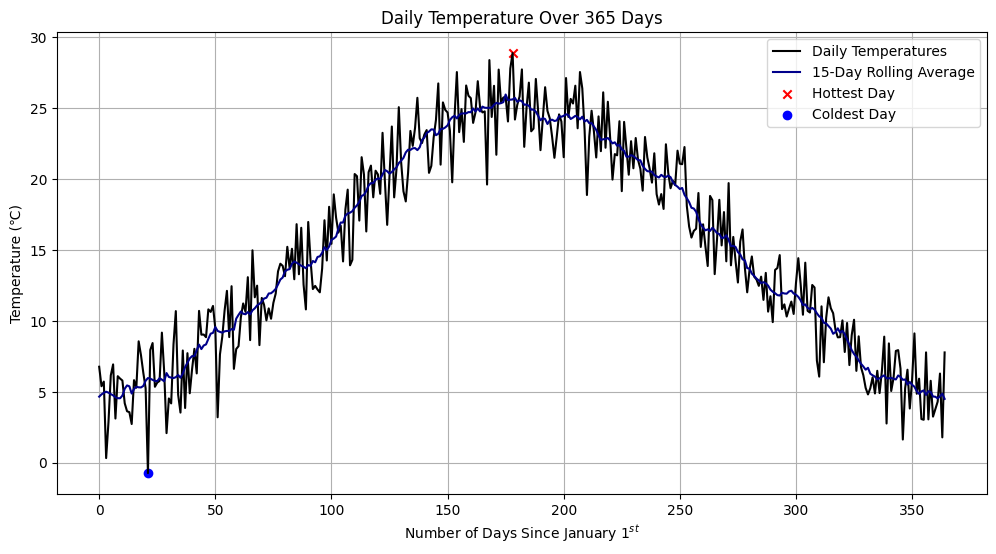

In [9]:
# Calls the plot_temperatures function
plot_temperatures(temperature_data)

### Comment on your plot: do the simulated data appear realistic?

- The plotted temperature data follows a sine wave like pattern, which becomes clearer when looking at the smooth $15$ day rolling average line.

- The daily temperature peaks around the middle of the year, corresponding to summer in the Northern Hemisphere.

- The lowest daily temperatures occur at the beginning and end of the year, which is when winter occurs in the Northern Hemisphere.

- The day-to-day variation in daily temperature is within a reasonable range of a few degrees and prevents the curve from being perfectly smooth. This variability makes the simulated data appear more realistic and representative of natural temperature behaviour, where small deviations from the ideal seasonal patterns are expected.

---

## Task 4: Build a basic monthly temperature class 

Create a **class** called `MonthlyWeather` that is initialised with **two attributes**: a Numpy array of temperature data, and a corresponding month name.

The class must have **methods** to:

 - Return the average temperature

 - Return the hottest and coldest temperature

 - Classify the month as "Cold", "Warm" or "Hot", based on some temperature thresholds (that you decide)

 - Return a string summary, e.g. `"June: Length=30 days, Avg=22.3C, Max=30.1C, Min=15.0C, Classified as Hot"`

### Class:

In [10]:
# MonhtlyWeather class to store and analyse monthly weather data
class MonthlyWeather:

    # Initialse class with month name and daily temperatures for the month
    def __init__(self, month_name, daily_temperatures):
        self.month_name = month_name
        self.daily_temperatures = daily_temperatures

    # Returns average temperature for the month
    def average_temperature(self):
        return np.mean(self.daily_temperatures)
    
    # Returns hottest temperatures for the month
    def hottest_month_temp(self):
        hottest_temp = np.max(self.daily_temperatures)

        return hottest_temp
    
    # Returns coldest temperatures for the month
    def coldest_month_temp(self):
        coldest_temp = np.min(self.daily_temperatures)

        return coldest_temp
    
    # Classifies the month based on the month's average temperature
    def classify_month(self):

        # Calls average temperature fucntion
        avg_temp = self.average_temperature()

        # Classifies the month based on the average temperature thresholds
        if avg_temp < 10:
            return "Cold"
        elif avg_temp < 20:
            return "Warm"
        else:
            return "Hot"
    
    # Returns a summary string for the month's weather data
    def summary(self):

        # Calls functions to get data for the month
        avg_temp = self.average_temperature()

        hottest_temp = self.hottest_month_temp()

        coldest_temp = self.coldest_month_temp()

        classification = self.classify_month()
        
        # Returns a summary string for the month's weather data
        return (f"{self.month_name}: Length = {len(self.daily_temperatures)} days, "
                    f"Average Temperature = {avg_temp:.2f}\u2103, "
                    f"Max Temperature = {hottest_temp:.2f}\u2103, "
                    f"Min Temperature = {coldest_temp:.2f}\u2103, "
                    f"Classified as {classification}")

### In the cell below, explain how you chose your temperature thresholds to classify a month as cold, warm or hot:

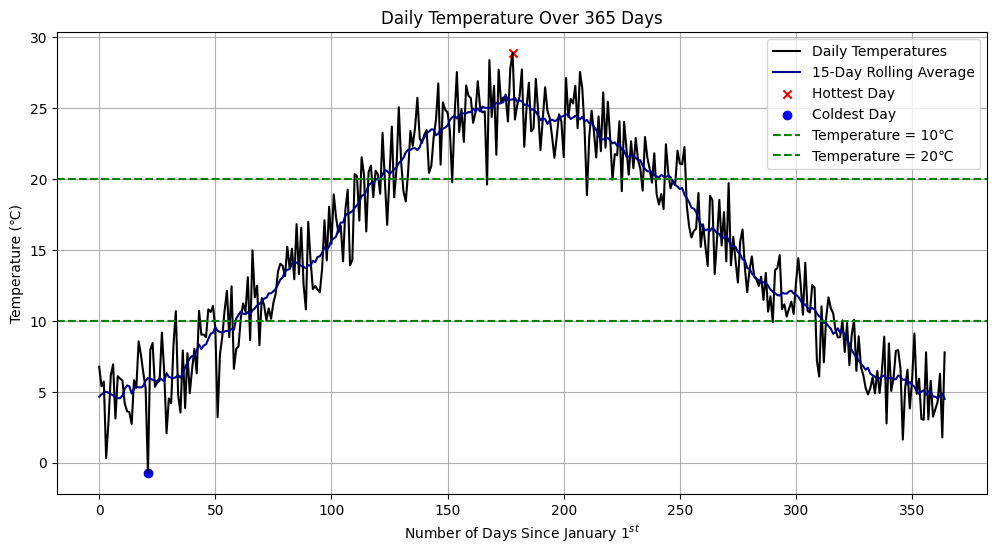

In [11]:
# Calls the plot_temperatures function
plot_temperatures(temperature_data)

# Plots a horizontal line at temperature = 10
plt.axhline(10, linestyle='dashed', color='green', label='Temperature = 10\u2103')

# Plots a horizontal line at temperature = 20
plt.axhline(20, linestyle='dashed', color='green', label='Temperature = 20\u2103')

# Displays legend and locks it to the top right
plt.legend(loc='upper right')

# Saves the plot as a png
plt.savefig("daily_temperatures_with_lines.png")

# Displays the plot
plt.show()

In [12]:
# Prints number of days classifed as cold, warm or hot respectively
print(len(temperature_data[temperature_data<10]))
print(len(temperature_data[temperature_data<20]) - len(temperature_data[temperature_data<10]))
print(len(temperature_data[temperature_data>=20]))

105
140
120


I chose my temperature thresholds by aiming to evenly categorise the daily temperatures by cold, warm or hot. On the graph we can see that when we plot a horizontal line at $10 ^\circ C$ and at $20 ^\circ C$ that the three regions appear evenly sized with data points. This visual assessment is confirmed by counting the number of data points each range, which showed that the three categories are approximately evenly distributed.

---

Now write a **function** `create_monthly_reports()` that takes a single argument (the temperature data over the course of a year).

The function must divide the year into 12 months, and use your `MonthlyWeather` class to produce a temperature summary for each month.
                                                                                                                      
It must return a list containing the 12 monthly summaries for the year.

You may again assume that a month is 30 days.

**Optional bonus:** write your function in a way that uses the true length for each month

### Function:

In [13]:
# Function that creates monthly weather reports from daily temperatures using real month lengths
def create_monthly_reports(temperatures):

    # List containing month names and their corresponding lengths
    month_info = [("January", 31), ("February", 28), ("March", 31), ("April", 30), ("May", 31), ("June", 30),
                  ("July", 31), ("August", 31), ("September", 30), ("October", 31), ("November", 30), ("December", 31)]

    # Empty list used to store monthly weather reports
    monthly_weather_reports = []

    # Start day for each month
    start_day = 0

    # Loops through each month
    for month_name, month_length in month_info:

        # Gets daily temperatures for the month
        month_temps = temperatures[start_day:start_day + month_length]
        
        # Creates MonthlyWeather instance
        month_weather = MonthlyWeather(month_name, month_temps)

        # Appends the month's summary to the reports list
        monthly_weather_reports.append(month_weather.summary())

        # Updates the start day for the next month
        start_day += month_length

    return monthly_weather_reports

### Execute function and **print the output**:

In [14]:
# Calls the create monthly reports function
monthly_weather_reports = create_monthly_reports(temperature_data)

# Prints the monthly weather reports
print("Monthly Weather Reports:")

# Loops through each report and print it
for report in monthly_weather_reports:
    print(f"    {report}")

Monthly Weather Reports:
    January: Length = 31 days, Average Temperature = 5.25℃, Max Temperature = 9.17℃, Min Temperature = -0.73℃, Classified as Cold
    February: Length = 28 days, Average Temperature = 8.11℃, Max Temperature = 12.45℃, Min Temperature = 3.20℃, Classified as Cold
    March: Length = 31 days, Average Temperature = 12.13℃, Max Temperature = 16.82℃, Min Temperature = 8.02℃, Classified as Warm
    April: Length = 30 days, Average Temperature = 16.80℃, Max Temperature = 21.54℃, Min Temperature = 12.01℃, Classified as Warm
    May: Length = 31 days, Average Temperature = 22.10℃, Max Temperature = 26.74℃, Min Temperature = 16.77℃, Classified as Hot
    June: Length = 30 days, Average Temperature = 24.99℃, Max Temperature = 28.88℃, Min Temperature = 19.62℃, Classified as Hot
    July: Length = 31 days, Average Temperature = 24.45℃, Max Temperature = 27.73℃, Min Temperature = 18.88℃, Classified as Hot
    August: Length = 31 days, Average Temperature = 21.82℃, Max Temperat

---

# Task 5: Model the data

Fit a model to the temperature data (using the full year). 

This model should consist of a sine or cosine wave plus a constant -- note that this is the same model you used to generate the data, but without the random day-to-day noise!

The free parameters must include (at least) the following:
 - amplitude of the sine/cosine wave
 - period or frequency of the wave
 - the value of the additive constant

Plot the temperature data again, and this time overlay the best-fit model.

Comment on how similar your best-fitting parameters are to the parameters used to generate the temperature data, and whether this is expected.

### Define your model:

In [15]:
# Function that generates daily temperature data without random noise
def temperature_model(day, amplitude, period, additive_constant):

    # Generates seasonal temperature variation using a sine wave
    seasonal_variation = amplitude * np.sin(2 * np.pi * day / period - np.pi / 2)

    # Combines seasonal variation and additive constant
    temps = seasonal_variation + additive_constant

    return temps

### Fit the model to the temperature data:


In [16]:
# Generates a numpy array of days from 0 to 364 ( January 1st = Index 0)
days = np.arange(len(temperature_data))

# Initial guess for the parameters: amplitude = 12, period = 400, additive constant = 20
initial_guess = [12, 400, 20]

# Uses curve_fit to find the best-fit parameters for the model
params, covariance = curve_fit(temperature_model, days, temperature_data, p0=initial_guess)

# Extracts the best-fit parameters from the params array
best_amplitude, best_period, best_additive_constant = params

### Print the best-fit parameters:

In [17]:
# Prints the best-fit parameters for the temperature model
print("Best-Fit Model Parameters:")
print(f"    Amplitude: {best_amplitude:.2f}")
print(f"    Period: {best_period:.2f}")
print(f"    Additive Constant: {best_additive_constant:.2f}")

Best-Fit Model Parameters:
    Amplitude: 10.01
    Period: 366.08
    Additive Constant: 15.05


### Are these parameters what you would expect?

Yes, these parameters are consistent with what we would expect. The best-fit model parameters are very close to the values originally used to generate the simulated data at the beginning. Small differences are expected because the fitted model does not include random day-to-day noise which is used in the simulated dataset.

### Use your earlier function to re-plot the data, and add the model fit:

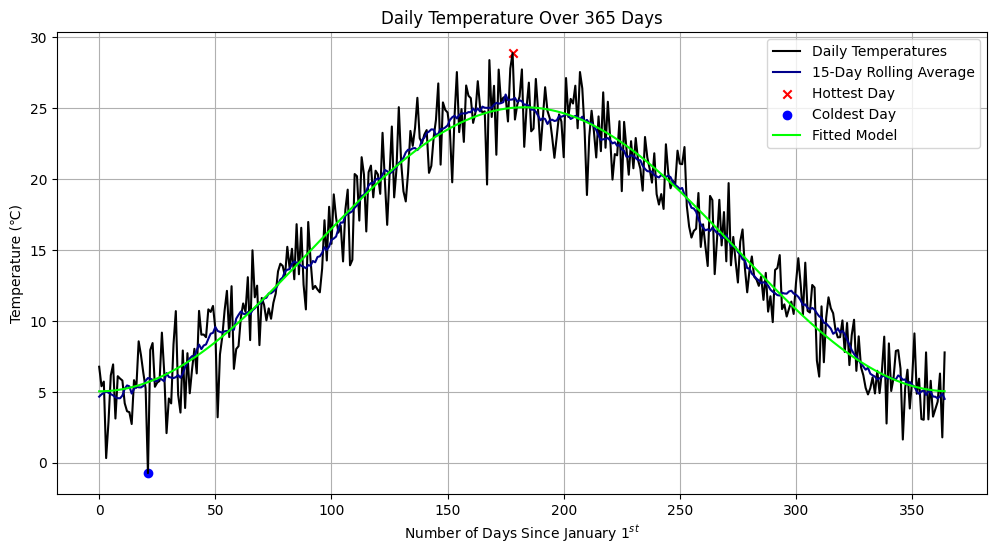

In [18]:
# Calls the temperature model function
model_fit = temperature_model(days, *params)

# Calls the plot_temperature function for the simulated temperature data with random noise
plot_temperatures(temperature_data)

# Plots the fitted temperature model without random noise
plt.plot(days, model_fit, label="Fitted Model", color="lime")

# Displays legend and locks it to the top right
plt.legend(loc = 'upper right')

# Saves the plot as a png
plt.savefig("temperature_model_fit.png")

# Displays the plot
plt.show()